In [71]:
##importing packages

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess
from scipy.stats import ttest_ind
import statsmodels.formula.api as smf
from statsmodels.gam.api import GLMGam, BSplines
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from scipy import stats



In [57]:
#lets get this new dataset going
df = pd.read_stata("/Users/dustinh/Downloads/framingham.dta")

df
df.columns

Index(['sex', 'totchol', 'age', 'sysbp', 'diabp', 'cursmoke', 'cigpday', 'bmi',
       'diabetes', 'bpmeds', 'heartrte', 'glucose', 'prevchd', 'prevap',
       'prevmi', 'prevstrk', 'prevhyp', 'death', 'angina', 'hospmi', 'mi_fchd',
       'anychd', 'stroke', 'cvd', 'hyperten', 'timeap', 'timemi', 'timemifc',
       'timechd', 'timestrk', 'timecvd', 'timedth', 'timehyp', 'bmicat',
       'agecat', 'obese_normal'],
      dtype='object')

In [58]:
#first we have to build our outcome category for
mn_df = df[df["prevchd"] == 0].copy()

#It's a three level outcome death takes priority over nonfatal CHD
# 0 = no death or CHD (reference), 1 = CHD alive, 2 = death from any cause
def make_outcome(row):
    if row["death"] == 1:
        return 2
    elif row["anychd"] == 1:
        return 1
    else:
        return 0

mn_df["outcome3"] = mn_df.apply(make_outcome, axis=1)
print(mn_df["outcome3"].value_counts())

outcome3
0    2370
2    1406
1     464
Name: count, dtype: int64


In [59]:
#now it's time we build our models. First 

#Model 1: age alone
m1 = smf.mnlogit("outcome3 ~ age", data=mn_df).fit()
print(m1.summary())

#recode sex: 1 = male stays 1, 2 = female becomes 0
mn_df["sex_male"] = mn_df["sex"].map({1: 1, 2: 0})

#Model 2: sex alone
m2 = smf.mnlogit("outcome3 ~ sex_male", data=mn_df).fit()
print(m2.summary())

#Model 3: age and sex
m3 = smf.mnlogit("outcome3 ~ age + C(sex)", data=mn_df).fit()
print(m3.summary())

#Model 4: age, sex, and their interaction
m4 = smf.mnlogit("outcome3 ~ age * C(sex)", data=mn_df).fit()
print(m4.summary())

Optimization terminated successfully.
         Current function value: 0.844766
         Iterations 6
                          MNLogit Regression Results                          
Dep. Variable:               outcome3   No. Observations:                 4240
Model:                        MNLogit   Df Residuals:                     4236
Method:                           MLE   Df Model:                            2
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.09484
Time:                        09:35:13   Log-Likelihood:                -3581.8
converged:                       True   LL-Null:                       -3957.1
Covariance Type:            nonrobust   LLR p-value:                1.032e-163
outcome3=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -2.8591      0.312     -9.167      0.000      -3.470      -2.248
age            0.0258      0.

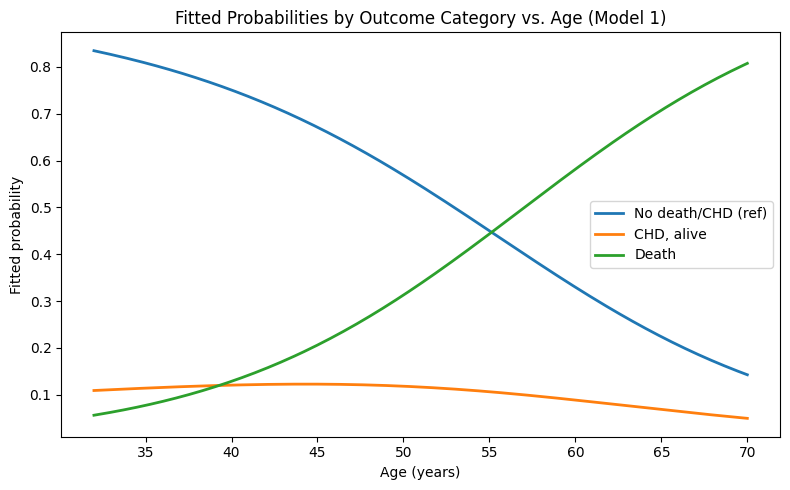

In [ ]:
#now let's calculate and graph the fitted probabilities for each outcome category as a function of age
#using Model 1 (age alone) since that's the model whose equation we wrote out above

age_grid = pd.DataFrame({"age": np.linspace(mn_df["age"].min(), mn_df["age"].max(), 200)})
fitted_probs = m1.predict(age_grid)
fitted_probs.columns = ["No death/CHD (ref)", "CHD, alive", "Death"]

fig, ax = plt.subplots(figsize=(8, 5))
for outcome in fitted_probs.columns:
    ax.plot(age_grid["age"], fitted_probs[outcome], lw=2, label=outcome)

ax.set_xlabel("Age (years)")
ax.set_ylabel("Fitted probability")
ax.set_title("Fitted Probabilities by Outcome Category vs. Age (Model 1)")
ax.legend()
plt.tight_layout()
plt.savefig("hw_6_fitted_probs_by_age.png", dpi=300)
plt.show()

In [61]:
#RRR and 95% CI for a 10-year increase in age, comparing outcome 2 (CHD, alive) to outcome 1 (reference)
#Model 1's "outcome3 = 1" equation (CHD alive vs. reference) gives us this comparison directly

beta_age = m1.params.loc["age", 0]
ci_low, ci_high = m1.conf_int().loc[("1", "age")]

rrr_10yr = np.exp(10 * beta_age)
rrr_10yr_low = np.exp(10 * ci_low)
rrr_10yr_high = np.exp(10 * ci_high)

print(f"RRR for 10 years of age (outcome 2 vs outcome 1): {rrr_10yr:.3f}")
print(f"95% CI: ({rrr_10yr_low:.3f}, {rrr_10yr_high:.3f})")

RRR for 10 years of age (outcome 2 vs outcome 1): 1.294
95% CI: (1.142, 1.467)


In [ ]:
#RRR and 95% CI for a 10-year increase in age, comparing outcome 3 (death) to outcome 1 (reference)
#Model 1's "outcome3 = 2" equation (death vs. reference)

beta_age_death = m1.params.loc["age", 1]
ci_low_death, ci_high_death = m1.conf_int().loc[("2", "age")]

rrr_10yr_death = np.exp(10 * beta_age_death)
rrr_10yr_death_low = np.exp(10 * ci_low_death)
rrr_10yr_death_high = np.exp(10 * ci_high_death)

print(f"RRR for 10 years of age (outcome 3 vs outcome 1): {rrr_10yr_death:.3f}")
print(f"95% CI: ({rrr_10yr_death_low:.3f}, {rrr_10yr_death_high:.3f})")

RRR for 10 years of age (outcome 3 vs outcome 1): 3.207
95% CI: (2.925, 3.516)


In [ ]:
#simplest way to get this directly: refit the model with outcome 2 (CHD, alive) as the reference
#category instead of outcome 1, so the age coefficient for death is relative to CHD-alive

recode_chdref = {1: 0, 0: 1, 2: 2}
mn_df["outcome3_chdref"] = mn_df["outcome3"].map(recode_chdref)

m1_chdref = smf.mnlogit("outcome3_chdref ~ age", data=mn_df).fit()
print(m1_chdref.summary())

beta_32 = m1_chdref.params.loc["age", 1]
ci_low_32, ci_high_32 = m1_chdref.conf_int().loc[("2", "age")]

rrr_10yr_32 = np.exp(10 * beta_32)
rrr_10yr_32_low = np.exp(10 * ci_low_32)
rrr_10yr_32_high = np.exp(10 * ci_high_32)

print(f"RRR for 10 years of age (outcome 3 vs outcome 2): {rrr_10yr_32:.3f}")
print(f"95% CI: ({rrr_10yr_32_low:.3f}, {rrr_10yr_32_high:.3f})")

Optimization terminated successfully.
         Current function value: 0.844766
         Iterations 6
                          MNLogit Regression Results                          
Dep. Variable:        outcome3_chdref   No. Observations:                 4240
Model:                        MNLogit   Df Residuals:                     4236
Method:                           MLE   Df Model:                            2
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.09484
Time:                        09:35:13   Log-Likelihood:                -3581.8
converged:                       True   LL-Null:                       -3957.1
Covariance Type:            nonrobust   LLR p-value:                1.032e-163
outcome3_chdref=1       coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             2.8591      0.312      9.167      0.000       2.248       3.470
age     

In [64]:
# I am going to need to recode the sex variable
mn_df["sex_male"] = mn_df["sex"].map({1: 1, 2: 0})

#Model 2: sex alone
m2 = smf.mnlogit("outcome3 ~ sex_male", data=mn_df).fit()
print(m2.summary())

new = pd.DataFrame({"sex_male": [0, 1]})
m2.predict(new)

Optimization terminated successfully.
         Current function value: 0.920851
         Iterations 6
                          MNLogit Regression Results                          
Dep. Variable:               outcome3   No. Observations:                 4240
Model:                        MNLogit   Df Residuals:                     4236
Method:                           MLE   Df Model:                            2
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                 0.01332
Time:                        09:35:13   Log-Likelihood:                -3904.4
converged:                       True   LL-Null:                       -3957.1
Covariance Type:            nonrobust   LLR p-value:                 1.311e-23
outcome3=1       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -1.8467      0.070    -26.533      0.000      -1.983      -1.710
sex_male       0.5117      0.

,0,1,2
0,0.626033,0.098760,0.275207
1,0.469780,0.123626,0.406593


In [69]:
#building cross tab table. I'ts just one command. Looks like it matches to the prediction values
pd.crosstab(mn_df["outcome3"], mn_df["sex_male"], normalize="columns")

#now let's compare to my predicted

predicted = pd.DataFrame(m2.predict(), index=mn_df.index).drop_duplicates()
predicted.index = mn_df.loc[predicted.index, "sex_male"]

observed = pd.crosstab(mn_df["sex_male"], mn_df["outcome3"], normalize="index")

print("Observed:")
print(observed)
print("\nPredicted:")
print(predicted)




Observed:
outcome3         0         1         2
sex_male                              
0         0.626033  0.098760  0.275207
1         0.469780  0.123626  0.406593

Predicted:
                 0         1         2
sex_male                              
1         0.469780  0.123626  0.406593
0         0.626033  0.098760  0.275207


In [ ]:
# Step 1: risk ratios within each sex from the tabulation
rr_2v1 = observed[1] / observed[0] 
rr_3v1 = observed[2] / observed[0]

# Step 2: relative risk ratios for sex (male / female), from the tabulation
rrr_2v1_tab = rr_2v1.loc[1] / rr_2v1.loc[0]
rrr_3v1_tab = rr_3v1.loc[1] / rr_3v1.loc[0]

# Step 3: RRRs from the model (exponentiated sex coefficients)
rrr_model = np.exp(m2.params.loc["sex_male"])

print("Tabulated RRR, 2 vs 1:", rrr_2v1_tab)
print("Tabulated RRR, 3 vs 1:", rrr_3v1_tab)
print("Model RRRs:\n", rrr_model)

Tabulated RRR, 2 vs 1: 1.6681347720766349
Tabulated RRR, 3 vs 1: 1.9688109161793368
Model RRRs:
 0    1.668135
1    1.968811
Name: sex_male, dtype: float64


In [73]:
#now we have to run some likliehood ratio caclucations 

#Likelihood ratio test comparing Model 3 (age + sex) to Model 4 (age + sex + interaction)
lr_stat = -2 * (m3.llf - m4.llf)
df_diff = m4.df_model - m3.df_model
p_value = stats.chi2.sf(lr_stat, df_diff)

print(p_value)


0.028127433862597095


In [ ]:
#now we are going ordinal 

#since our outcome is naturally ordered: 0 = no death/CHD < 1 = CHD, alive < 2 = death
from statsmodels.miscmodels.ordinal_model import OrderedModel

#need to build the interaction term manually since orderemodel doesn't use the formula interface
mn_df["age_sexmale"] = mn_df["age"] * mn_df["sex_male"]

#Model 1: age alone
om1 = OrderedModel(mn_df["outcome3"], mn_df[["age"]], distr="logit").fit(method="bfgs")
print(om1.summary())

#Model 2: sex alone
om2 = OrderedModel(mn_df["outcome3"], mn_df[["sex_male"]], distr="logit").fit(method="bfgs")

#Model 3: age and sex
om3 = OrderedModel(mn_df["outcome3"], mn_df[["age", "sex_male"]], distr="logit").fit(method="bfgs")

#Model 4: age, sex, and their interaction
om4 = OrderedModel(mn_df["outcome3"], mn_df[["age", "sex_male", "age_sexmale"]], distr="logit").fit(method="bfgs")



Optimization terminated successfully.
         Current function value: 0.850045
         Iterations: 13
         Function evaluations: 18
         Gradient evaluations: 18
                             OrderedModel Results                             
Dep. Variable:               outcome3   Log-Likelihood:                -3604.2
Model:                   OrderedModel   AIC:                             7214.
Method:            Maximum Likelihood   BIC:                             7233.
Date:                Sun, 25 Oct 2026                                         
Time:                        21:46:34                                         
No. Observations:                4240                                         
Df Residuals:                    4237                                         
Df Model:                           1                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------

In [77]:
# don't know if R is different, but I hvave to manually code oods ratio. It can't be done through the .summary() command

or_10yr = np.exp(10 * om1.params["age"])
ci_low, ci_high = np.exp(10 * om1.conf_int().loc["age"])

print(f"OR for 10 years of age (outcome 3 vs outcome 1&2 combined): {or_10yr:.3f}")
print(f"95% CI: ({ci_low:.3f}, {ci_high:.3f})")



OR for 10 years of age (outcome 3 vs outcome 1&2 combined): 2.701
95% CI: (2.498, 2.920)


In [78]:
#now we do the same thing for 2 and 3

or_10yr_v2 = np.exp(10 * om1.params["age"])
ci_low_v2, ci_high_v2 = np.exp(10 * om1.conf_int().loc["age"])

print(f"OR for 10 years of age (outcome 2&3 combined vs outcome 1): {or_10yr_v2:.3f}")
print(f"95% CI: ({ci_low_v2:.3f}, {ci_high_v2:.3f})")


OR for 10 years of age (outcome 2&3 combined vs outcome 1): 2.701
95% CI: (2.498, 2.920)


In [ ]:
#assessing the proportional odds assumption for the age-alone model

#binary outcome 1: category 3 (death) = 1, categories 1 and 2 combined = 0
mn_df["bin_3vs12"] = (mn_df["outcome3"] == 2).astype(int)
logit_3vs12 = smf.logit("bin_3vs12 ~ age", data=mn_df).fit()
print(logit_3vs12.summary())

#binary outcome 2: categories 2 and 3 combined = 1, category 1 = 0
mn_df["bin_23vs1"] = (mn_df["outcome3"].isin([1, 2])).astype(int)
logit_23vs1 = smf.logit("bin_23vs1 ~ age", data=mn_df).fit()
print(logit_23vs1.summary()


Optimization terminated successfully.
         Current function value: 0.548692
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:              bin_3vs12   No. Observations:                 4240
Model:                          Logit   Df Residuals:                     4238
Method:                           MLE   Df Model:                            1
Date:                Sun, 25 Oct 2026   Pseudo R-squ.:                  0.1363
Time:                        22:01:28   Log-Likelihood:                -2326.5
converged:                       True   LL-Null:                       -2693.7
Covariance Type:            nonrobust   LLR p-value:                9.369e-162
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -6.3843      0.237    -26.937      0.000      -6.849      -5.920
age            0.1119      0.

In [82]:
#Time to run an LRT test

lr_stat = -2 * (om3.llf - m3.llf)
df_diff = m3.params.size - len(om3.params)
p_value = stats.chi2.sf(lr_stat, df_diff)

print(lr_stat)
print(df_diff)
print(p_value)


37.858176573841774
2
6.014526040276397e-09
